In [45]:
import json
import hashlib
import random
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import pennylane as qml

from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from torch_geometric.data import HeteroData
from torch_geometric.nn import HeteroConv, SAGEConv
from torch_geometric.transforms import ToUndirected

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss, precision_recall_curve

from tqdm.auto import tqdm

# Variable

In [46]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")

CLASSICAL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUANTUM_DEVICE = torch.device("cpu")
ROOT = Path("./data/qguard/dataset")
CHECKPOINT_DIR = Path("./checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

MAX_SEQ_LEN = 30
HIDDEN_DIM = 32

N_QUBITS = 4
N_LAYERS = 3

DROPOUT = 0.10

BATCH_SIZE = 256
CLASSICAL_EPOCHS = 200
QUANTUM_EPOCHS = 100

CLASSICAL_LR = 1e-3
QUANTUM_LR = 3e-4

SCHEDULER_TYPE = "plateau"  # "plateau" or "cosine"
EARLY_STOP_PATIENCE = 8

PLOTS_DIR = Path("./Plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

DASHBOARD_DIR = Path("./qguard_checkpoint_review")

EXPORT_DIR = DASHBOARD_DIR / "exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loader

In [3]:
raw_names = [
    "accounts",
    "transactions",
    "sessions",
    "payment_events",
    "devices",
    "networks"
]

public = {
    name: pd.read_parquet(
        ROOT / "raw" / f"{name}.parquet"
    )
    for name in raw_names
}

private = {
    name: pd.read_parquet(
        ROOT / "private" / f"{name}.parquet"
    )
    for name in ["persons", "ownership"]
}

manifest = json.loads(
    (ROOT / "manifest.json").read_text()
)

SIM_START = pd.Timestamp(manifest["sim_start_utc"])
SNAPSHOT = SIM_START + pd.Timedelta(days=90)

for name in ["transactions", "sessions", "payment_events"]:
    public[name]["timestamp"] = pd.to_datetime(
        public[name]["timestamp"],
        utc=True
    )

# Splits household

In [4]:
persons = private["persons"]
ownership = private["ownership"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_rows, val_rows = next(
    splitter.split(
        persons,
        groups=persons["household_id"]
    )
)

train_person_ids = set(
    persons.iloc[train_rows]["person_id"]
)

val_person_ids = set(
    persons.iloc[val_rows]["person_id"]
)

train_account_ids = set(
    ownership.loc[
        ownership["person_id"].isin(train_person_ids),
        "account_id"
    ]
)

val_account_ids = set(
    ownership.loc[
        ownership["person_id"].isin(val_person_ids),
        "account_id"
    ]
)

In [5]:
def create_view(account_ids):
    ids = set(account_ids)

    view = {}

    for name in [
        "accounts",
        "transactions",
        "sessions",
        "payment_events"
    ]:
        frame = public[name]

        view[name] = frame[
            frame["account_id"].isin(ids)
        ].copy()

    for name in [
        "transactions",
        "sessions",
        "payment_events"
    ]:
        view[name] = view[name][
            view[name]["timestamp"] < SNAPSHOT
        ].copy()

    return view


train_view = create_view(train_account_ids)
val_view = create_view(val_account_ids)

In [6]:
def make_account_map(view):
    ids = sorted(
        view["accounts"]["account_id"].unique()
    )

    return {
        account_id: index
        for index, account_id in enumerate(ids)
    }


train_map = make_account_map(train_view)
val_map = make_account_map(val_view)

# Temporal features

In [7]:
TEMPORAL_FEATURES = [
    "log_amount",
    "is_deposit",
    "is_wager",
    "is_withdrawal",
    "is_payout",
    "is_approved",
    "log_gap_hours",
    "hour_sin",
    "hour_cos",
    "is_weekend"
]

def make_sequences(view, account_map):
    tx = view["transactions"].copy()

    tx = tx.sort_values(
        ["account_id", "timestamp", "transaction_id"]
    )

    tx["log_amount"] = np.log1p(
        tx["amount_cad"].clip(lower=0)
    )

    for kind in [
        "deposit", "wager", "withdrawal", "payout"
    ]:
        tx[f"is_{kind}"] = (
            tx["transaction_type"] == kind
        ).astype(np.float32)

    tx["is_approved"] = (
        tx["status"] == "approved"
    ).astype(np.float32)

    gap_hours = (
        tx.groupby("account_id")["timestamp"]
        .diff()
        .dt.total_seconds()
        .div(3600)
        .fillna(0)
        .clip(lower=0, upper=720)
    )

    tx["log_gap_hours"] = np.log1p(gap_hours)

    hour = (
        tx["timestamp"].dt.hour
        + tx["timestamp"].dt.minute / 60
    )

    tx["hour_sin"] = np.sin(
        2 * np.pi * hour / 24
    )

    tx["hour_cos"] = np.cos(
        2 * np.pi * hour / 24
    )

    tx["is_weekend"] = (
        tx["timestamp"].dt.dayofweek >= 5
    ).astype(np.float32)

    N = len(account_map)

    X = np.zeros(
        (N, MAX_SEQ_LEN, len(TEMPORAL_FEATURES)),
        dtype=np.float32
    )

    lengths = np.zeros(N, dtype=np.int64)

    for account_id, group in tx.groupby("account_id"):
        i = account_map[account_id]

        values = (
            group[TEMPORAL_FEATURES]
            .tail(MAX_SEQ_LEN)
            .to_numpy(dtype=np.float32)
        )

        n = len(values)

        X[i, :n] = values
        lengths[i] = n

    return (
        torch.from_numpy(X),
        torch.from_numpy(lengths)
    )

In [8]:
train_sequences, train_lengths = make_sequences(
    train_view, train_map
)

val_sequences, val_lengths = make_sequences(
    val_view, val_map
)

# Graph construction

In [9]:
network_types = public["networks"].set_index(
    "network_id"
)["network_type"].to_dict()


def make_graph(view, account_map):
    s = view["sessions"]
    p = view["payment_events"]

    # Remove public networks from graph topology.
    sn = s[
        s["network_id"].map(network_types) != "public"
    ]

    node_ids = {
        "account": list(account_map),
        "device": sorted(s["device_id"].dropna().unique()),
        "network": sorted(sn["network_id"].dropna().unique()),
        "payment": sorted(p["payment_token"].dropna().unique())
    }

    node_map = {
        kind: {
            node_id: i
            for i, node_id in enumerate(ids)
        }
        for kind, ids in node_ids.items()
    }

    def counts(frame, column=None):
        grouped = frame.groupby("account_id")

        series = (
            grouped.size()
            if column is None
            else grouped[column].nunique()
        )

        return series.reindex(
            node_ids["account"],
            fill_value=0
        ).to_numpy(dtype=np.float32)

    account_x = np.column_stack([
        counts(s),
        counts(s, "device_id"),
        counts(s, "network_id"),
        counts(p),
        counts(p, "payment_token")
    ])

    graph = HeteroData()

    graph["account"].x = torch.tensor(
        np.log1p(account_x),
        dtype=torch.float32
    )

    def resource_x(frame, column, ids):
        grouped = frame.groupby(column)

        events = grouped.size().reindex(
            ids, fill_value=0
        ).to_numpy(dtype=np.float32)

        accounts = grouped["account_id"].nunique().reindex(
            ids, fill_value=0
        ).to_numpy(dtype=np.float32)

        return torch.tensor(
            np.column_stack([
                np.ones(len(ids), dtype=np.float32),
                np.log1p(events),
                np.log1p(accounts)
            ]),
            dtype=torch.float32
        )

    graph["device"].x = resource_x(
        s, "device_id", node_ids["device"]
    )

    graph["network"].x = resource_x(
        sn, "network_id", node_ids["network"]
    )

    graph["payment"].x = resource_x(
        p, "payment_token", node_ids["payment"]
    )

    relations = [
        (s, "device_id", "device", "uses_device"),
        (sn, "network_id", "network", "connects_from"),
        (p, "payment_token", "payment", "uses_payment")
    ]

    for frame, column, node_type, relation in relations:
        pairs = frame[
            ["account_id", column]
        ].dropna().drop_duplicates()

        src = pairs["account_id"].map(
            account_map
        ).to_numpy(dtype=np.int64)

        dst = pairs[column].map(
            node_map[node_type]
        ).to_numpy(dtype=np.int64)

        graph[
            "account", relation, node_type
        ].edge_index = torch.tensor(
            np.stack([src, dst]),
            dtype=torch.long
        )

    return ToUndirected()(graph)

train_graph = make_graph(train_view, train_map)
val_graph = make_graph(val_view, val_map)

# Positive pair generations

In [10]:
owner_by_account = ownership.set_index(
    "account_id"
)["person_id"].to_dict()


def make_positive_pairs(account_map):
    owned = ownership[
        ownership["account_id"].isin(account_map)
    ]

    positives = set()

    for _, group in owned.groupby("person_id"):
        ids = [
            account_map[a]
            for a in group["account_id"]
        ]

        positives.update(
            combinations(sorted(ids), 2)
        )

    return positives

def make_candidates(view, account_map):
    s = view["sessions"]
    p = view["payment_events"]

    sn = s[
        s["network_id"].map(network_types) != "public"
    ]

    candidates = set()

    sources = [
        (s, "device_id"),
        (p, "payment_token"),
        (sn, "network_id")
    ]

    for frame, column in sources:
        relations = frame[
            ["account_id", column]
        ].dropna().drop_duplicates()

        for _, group in relations.groupby(column):
            ids = sorted({
                account_map[a]
                for a in group["account_id"]
            })

            # Prevent very large shared-entity cliques.
            if len(ids) > 20:
                continue

            candidates.update(combinations(ids, 2))

    return candidates

In [11]:
household_by_person = persons.set_index(
    "person_id"
)["household_id"].to_dict()


def make_training_pairs(view, account_map, ratio=3):
    rng = np.random.default_rng(SEED)

    positives = make_positive_pairs(account_map)
    candidates = make_candidates(view, account_map)

    # Candidate negatives identified using private truth.
    hard = {
        pair for pair in candidates
        if owner_by_account[
            list(account_map)[pair[0]]
        ] != owner_by_account[
            list(account_map)[pair[1]]
        ]
    }

    # Different owners in the same household.
    local_ownership = ownership[
        ownership["account_id"].isin(account_map)
    ].copy()

    local_ownership["household_id"] = (
        local_ownership["person_id"]
        .map(household_by_person)
    )

    account_ids = list(account_map)

    for _, group in local_ownership.groupby("household_id"):
        ids = sorted(
            account_map[a]
            for a in group["account_id"]
        )

        for pair in combinations(ids, 2):
            a, b = pair

            if owner_by_account[account_ids[a]] != \
               owner_by_account[account_ids[b]]:
                hard.add(pair)

    n_neg = ratio * len(positives)

    hard_list = sorted(hard - positives)

    n_hard = min(
        len(hard_list),
        n_neg * 2 // 3
    )

    chosen = set()

    if n_hard:
        indices = rng.choice(
            len(hard_list),
            size=n_hard,
            replace=False
        )

        chosen.update(hard_list[i] for i in indices)

    while len(chosen) < n_neg:
        a, b = sorted(
            rng.choice(
                len(account_map),
                size=2,
                replace=False
            ).tolist()
        )

        pair = (a, b)

        if pair not in positives:
            chosen.add(pair)

    all_pairs = sorted(positives) + sorted(chosen)

    all_labels = (
        [1.0] * len(positives)
        + [0.0] * len(chosen)
    )

    return all_pairs, all_labels

In [12]:
train_pairs, train_labels = make_training_pairs(
    train_view, train_map
)

val_positive_pairs = make_positive_pairs(val_map)
val_candidates = sorted(
    make_candidates(val_view, val_map)
)

val_pairs = val_candidates

val_labels = [
    float(pair in val_positive_pairs)
    for pair in val_pairs
]

candidate_recall = (
    len(set(val_pairs) & val_positive_pairs)
    / max(len(val_positive_pairs), 1)
)

In [13]:
def make_pair_loader(
    pairs,
    labels,
    batch_size=BATCH_SIZE,
    shuffle=False
):
    X = torch.tensor(
        pairs, dtype=torch.long
    )

    y = torch.tensor(
        labels, dtype=torch.float32
    )

    dataset = TensorDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0
    )


train_loader = make_pair_loader(
    train_pairs, train_labels, shuffle=True
)

val_loader = make_pair_loader(
    val_pairs, val_labels
)

# Temporal GRU

In [14]:
class TemporalGRU(nn.Module):
    def __init__(self, input_dim=10, hidden_dim=32):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x,
            lengths.clamp_min(1).cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(packed)

        h = self.norm(hidden[-1])

        return h.masked_fill(
            (lengths == 0).to(h.device).unsqueeze(1),
            0.0
        )

# Heterogeneous GraphSAGE

In [15]:
class HeteroGraphSAGE(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()

        self.to_resources = HeteroConv({
            ("account", "uses_device", "device"):
                SAGEConv((-1, -1), hidden_dim),

            ("account", "connects_from", "network"):
                SAGEConv((-1, -1), hidden_dim),

            ("account", "uses_payment", "payment"):
                SAGEConv((-1, -1), hidden_dim)
        }, aggr="sum")

        self.to_accounts = HeteroConv({
            ("device", "rev_uses_device", "account"):
                SAGEConv((-1, -1), hidden_dim),

            ("network", "rev_connects_from", "account"):
                SAGEConv((-1, -1), hidden_dim),

            ("payment", "rev_uses_payment", "account"):
                SAGEConv((-1, -1), hidden_dim)
        }, aggr="sum")

        self.skip = nn.Linear(5, hidden_dim)
        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, graph):
        resources = self.to_resources(
            graph.x_dict,
            graph.edge_index_dict
        )

        resource_x = {
            "account": graph["account"].x,
            "device": F.relu(resources["device"]),
            "network": F.relu(resources["network"]),
            "payment": F.relu(resources["payment"])
        }

        account_h = self.to_accounts(
            resource_x,
            graph.edge_index_dict
        )["account"]

        account_h = (
            account_h + self.skip(graph["account"].x)
        )

        return self.norm(F.relu(account_h))

# Classical Fusion

In [16]:
class ClassicalFusion(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.GELU(),
            nn.LayerNorm(hidden_dim),
            nn.Dropout(DROPOUT)
        )

    def forward(self, temporal_h, graph_h):
        return self.net(
            torch.cat([temporal_h, graph_h], dim=-1)
        )

# Account Pair Decoder

In [17]:
class AccountPairDecoder(nn.Module):
    def __init__(self, embed_dim=32):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim * 2, 32),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(32, 1)
        )

    def forward(self, embeddings, pairs):
        a = embeddings[pairs[:, 0]]
        b = embeddings[pairs[:, 1]]

        features = torch.cat([
            torch.abs(a - b),
            a * b
        ], dim=-1)

        return self.classifier(features).squeeze(-1)

# QGuardClassical

In [18]:
class QGuardClassical(nn.Module):
    def __init__(self):
        super().__init__()

        self.temporal = TemporalGRU(
            input_dim=len(TEMPORAL_FEATURES),
            hidden_dim=HIDDEN_DIM
        )

        self.graph_encoder = HeteroGraphSAGE(
            hidden_dim=HIDDEN_DIM
        )

        self.fusion = ClassicalFusion(HIDDEN_DIM)
        self.decoder = AccountPairDecoder(HIDDEN_DIM)

    def encode_branches(self, sequences, lengths, graph):
        # Chunk GRU execution to reduce peak memory.
        temporal_parts = []

        for start in range(0, len(sequences), 1024):
            stop = start + 1024

            part = self.temporal(
                sequences[start:stop],
                lengths[start:stop]
            )

            temporal_parts.append(part)

        ht = torch.cat(temporal_parts, dim=0)
        hg = self.graph_encoder(graph)

        return ht, hg

    def encode(self, sequences, lengths, graph):
        ht, hg = self.encode_branches(
            sequences, lengths, graph
        )

        return self.fusion(ht, hg)

    def decode(self, embeddings, pairs):
        return self.decoder(embeddings, pairs)

# Quantum Fusion Qubits Prep

In [19]:
qdev = qml.device(
    "default.qubit",
    wires=N_QUBITS
)

@qml.qnode(
    qdev,
    interface="torch",
    diff_method="backprop"
)
def quantum_circuit(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(N_QUBITS),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights,
        wires=range(N_QUBITS)
    )

    return [
        qml.expval(qml.PauliZ(i))
        for i in range(N_QUBITS)
    ]

# Quantum Fusion

In [20]:
class QuantumFusion(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()

        self.temporal_projection = nn.Linear(
            hidden_dim, 2
        )

        self.graph_projection = nn.Linear(
            hidden_dim, 2
        )

        weight_shapes = {
            "weights": (N_LAYERS, N_QUBITS, 3)
        }

        self.quantum = qml.qnn.TorchLayer(
            quantum_circuit,
            weight_shapes
        )

        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2 + N_QUBITS, 32),
            nn.GELU(),
            nn.LayerNorm(32),
            nn.Dropout(DROPOUT)
        )

    def forward(self, temporal_h, graph_h):
        t = self.temporal_projection(temporal_h)
        g = self.graph_projection(graph_h)

        angles = torch.pi * torch.tanh(
            torch.cat([t, g], dim=-1)
        )

        quantum_h = self.quantum(angles)

        combined = torch.cat([
            temporal_h,
            graph_h,
            quantum_h.to(temporal_h.dtype)
        ], dim=-1)

        return self.fusion(combined)

# Classical frozen-encoder

In [21]:
class FrozenClassicalLink(nn.Module):
    def __init__(self):
        super().__init__()

        self.fusion = ClassicalFusion(HIDDEN_DIM)
        self.decoder = AccountPairDecoder(HIDDEN_DIM)

    def forward(self, ht, hg, pairs):
        unique_ids, inverse = torch.unique(
            pairs.flatten(),
            sorted=True,
            return_inverse=True
        )

        fused = self.fusion(
            ht[unique_ids],
            hg[unique_ids]
        )

        local_pairs = inverse.reshape(-1, 2)

        return self.decoder(fused, local_pairs)

# Quantum Hybrid Account Links

In [22]:
class QGuardQuantumLink(nn.Module):
    def __init__(self):
        super().__init__()

        self.fusion = QuantumFusion(HIDDEN_DIM)
        self.decoder = AccountPairDecoder(HIDDEN_DIM)

    def forward(self, ht, hg, pairs):
        unique_ids, inverse = torch.unique(
            pairs.flatten(),
            sorted=True,
            return_inverse=True
        )

        fused = self.fusion(
            ht[unique_ids],
            hg[unique_ids]
        )

        local_pairs = inverse.reshape(-1, 2)

        return self.decoder(fused, local_pairs)

# Classical Trains

In [23]:
classical_model = QGuardClassical().to(
    CLASSICAL_DEVICE
)

optimizer = torch.optim.AdamW(
    classical_model.parameters(),
    lr=CLASSICAL_LR,
    weight_decay=1e-4
)

train_X = train_sequences.to(CLASSICAL_DEVICE)
train_L = train_lengths.to(CLASSICAL_DEVICE)
train_G = train_graph.to(CLASSICAL_DEVICE)

val_X = val_sequences.to(CLASSICAL_DEVICE)
val_L = val_lengths.to(CLASSICAL_DEVICE)
val_G = val_graph.to(CLASSICAL_DEVICE)

C:\Users\fmontalfu\AppData\Local\Temp\ipykernel_13592\3491328954.py:5: UserWarning: There exist node types ({'account'}) whose representations do not get updated during message passing as they do not occur as destination type in any edge type. This may lead to unexpected behavior.
  self.to_resources = HeteroConv({
C:\Users\fmontalfu\AppData\Local\Temp\ipykernel_13592\3491328954.py:16: UserWarning: There exist node types ({'payment', 'device', 'network'}) whose representations do not get updated during message passing as they do not occur as destination type in any edge type. This may lead to unexpected behavior.
  self.to_accounts = HeteroConv({


In [24]:
def train_classical_epoch(model, loader, optimizer):
    model.train()
    optimizer.zero_grad()

    embeddings = model.encode(
        train_X, train_L, train_G
    )

    total_loss = torch.zeros(
        (), device=CLASSICAL_DEVICE
    )

    n_samples = 0

    for pairs, targets in loader:
        pairs = pairs.to(CLASSICAL_DEVICE)
        targets = targets.to(CLASSICAL_DEVICE)

        logits = model.decode(embeddings, pairs)

        total_loss = total_loss + F.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="sum"
        )

        n_samples += len(targets)

    loss = total_loss / n_samples

    loss.backward()

    nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=1.0
    )

    optimizer.step()

    return loss.item()

@torch.no_grad()
def evaluate_classical(model, loader):
    model.eval()

    embeddings = model.encode(
        val_X, val_L, val_G
    )

    probabilities = []
    targets_all = []

    for pairs, targets in loader:
        pairs = pairs.to(CLASSICAL_DEVICE)

        logits = model.decode(embeddings, pairs)

        probabilities.append(
            torch.sigmoid(logits).cpu()
        )

        targets_all.append(targets)

    y_true = torch.cat(targets_all).numpy()
    y_score = torch.cat(probabilities).numpy()

    ap = average_precision_score(
        y_true, y_score
    )

    return ap, y_true, y_score

In [25]:
classical_history = []

best_classical_ap = -1.0
patience = 15
stale_epochs = 0

for epoch in tqdm(range(CLASSICAL_EPOCHS)):
    train_loss = train_classical_epoch(
        classical_model,
        train_loader,
        optimizer
    )

    val_ap, _, _ = evaluate_classical(
        classical_model,
        val_loader
    )

    classical_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_ap": val_ap
    })

    if val_ap > best_classical_ap:
        best_classical_ap = val_ap
        stale_epochs = 0

        torch.save(
            classical_model.state_dict(),
            CHECKPOINT_DIR / "encoder_best.pt"
        )
    else:
        stale_epochs += 1

    if stale_epochs >= patience:
        break

classical_history = pd.DataFrame(
    classical_history
)

100%|██████████| 200/200 [08:24<00:00,  2.52s/it]


In [26]:
classical_model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "encoder_best.pt",
        map_location=CLASSICAL_DEVICE,
        weights_only=True
    )
)

classical_model.eval()

@torch.no_grad()
def cache_embeddings(model, X, lengths, graph):
    ht, hg = model.encode_branches(
        X, lengths, graph
    )

    return (
        ht.detach().cpu().contiguous(),
        hg.detach().cpu().contiguous()
    )


train_ht, train_hg = cache_embeddings(
    classical_model,
    train_X,
    train_L,
    train_G
)

val_ht, val_hg = cache_embeddings(
    classical_model,
    val_X,
    val_L,
    val_G
)


# Quantum trains

In [27]:
MAX_FUSION_PAIRS = 250000

rng = np.random.default_rng(SEED)

selected = rng.choice(
    len(train_pairs),
    size=min(MAX_FUSION_PAIRS, len(train_pairs)),
    replace=False
)

fusion_pairs = np.asarray(
    train_pairs,
    dtype=np.int64
)[selected]

fusion_labels = np.asarray(
    train_labels,
    dtype=np.float32
)[selected]

fusion_loader = make_pair_loader(
    fusion_pairs,
    fusion_labels,
    batch_size=64,
    shuffle=True
)

In [28]:
def train_fusion_epoch(
    model,
    loader,
    ht,
    hg,
    optimizer
):
    model.train()

    total_loss = 0.0
    total_samples = 0

    for pairs, targets in loader:
        optimizer.zero_grad()

        logits = model(ht, hg, pairs)

        loss = F.binary_cross_entropy_with_logits(
            logits,
            targets
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * len(targets)
        total_samples += len(targets)

    return total_loss / total_samples

@torch.no_grad()
def evaluate_fusion(model, loader, ht, hg):
    model.eval()

    probabilities = []
    labels = []

    for pairs, targets in loader:
        logits = model(ht, hg, pairs)

        probabilities.append(
            torch.sigmoid(logits).cpu()
        )

        labels.append(targets.cpu())

    y_true = torch.cat(labels).numpy()
    y_score = torch.cat(probabilities).numpy()

    return {
        "ap": average_precision_score(y_true, y_score),
        "y_true": y_true,
        "y_score": y_score
    }

# Main train

In [29]:
def make_quantum_optimizer(model):
    return torch.optim.AdamW([
        {
            "params": model.fusion.quantum.parameters(),
            "lr": 1e-3,
            "weight_decay": 0.0,
            "name": "vqc"
        },
        {
            "params": model.fusion.temporal_projection.parameters(),
            "lr": 3e-4,
            "weight_decay": 1e-4,
            "name": "temporal"
        },
        {
            "params": model.fusion.graph_projection.parameters(),
            "lr": 3e-4,
            "weight_decay": 1e-4,
            "name": "graph"
        },
        {
            "params": model.fusion.fusion.parameters(),
            "lr": 5e-4,
            "weight_decay": 1e-4,
            "name": "fusion"
        },
        {
            "params": model.decoder.parameters(),
            "lr": 5e-4,
            "weight_decay": 1e-4,
            "name": "decoder"
        }
    ])

In [30]:
def make_scheduler(optimizer, epochs, scheduler_type="plateau"):
    if scheduler_type == "plateau":
        return torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.7,
            patience=4,
            threshold=1e-4,
            min_lr=1e-5
        )

    elif scheduler_type == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
            eta_min=1e-6
        )

    else:
        raise ValueError(
            f"Unknown scheduler: {scheduler_type}"
        )

In [31]:
def fit_fusion(
    model,
    name,
    epochs=QUANTUM_EPOCHS,
    scheduler_type=SCHEDULER_TYPE
):
    # Different optimizer configuration for quantum fusion.
    if name == "Quantum":
        optimizer = make_quantum_optimizer(model)
    else:
        optimizer = torch.optim.AdamW([
            {
                "params": model.parameters(),
                "lr": 5e-4,
                "weight_decay": 1e-4,
                "name": "classical"
            }
        ])

    scheduler = make_scheduler(
        optimizer,
        epochs,
        scheduler_type
    )

    records = []
    best_ap = -float("inf")
    stale_epochs = 0

    checkpoint_path = (
        CHECKPOINT_DIR / f"{name}_best.pt"
    )

    for epoch in tqdm(range(epochs), desc=name):

        # Training
        train_loss = train_fusion_epoch(
            model,
            fusion_loader,
            train_ht,
            train_hg,
            optimizer
        )

        # Validation
        result = evaluate_fusion(
            model,
            val_loader,
            val_ht,
            val_hg
        )

        val_ap = result["ap"]

        # Record learning rates used during this epoch.
        lr_record = {
            f"lr_{group['name']}": group["lr"]
            for group in optimizer.param_groups
        }

        records.append({
            "epoch": epoch + 1,
            "model": name,
            "train_loss": train_loss,
            "val_ap": val_ap,
            **lr_record
        })

        # Best model checkpoint
        if val_ap > best_ap:
            best_ap = val_ap
            stale_epochs = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        else:
            stale_epochs += 1

        # Scheduler update
        if scheduler_type == "plateau":
            scheduler.step(val_ap)
        else:
            scheduler.step()

        # Early stopping
        if stale_epochs >= EARLY_STOP_PATIENCE:
            break

    history = pd.DataFrame(records)

    history.to_csv(
        CHECKPOINT_DIR / f"{name}_history.csv",
        index=False
    )

    return history

In [32]:
frozen_classical = FrozenClassicalLink()

classical_fusion_history = fit_fusion(
    frozen_classical,
    name="Classical",
    epochs=QUANTUM_EPOCHS
)

quantum_model = QGuardQuantumLink()

quantum_history = fit_fusion(
    quantum_model,
    name="Quantum",
    epochs=QUANTUM_EPOCHS
)

frozen_classical.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "Classical_best.pt",
        weights_only=True
    )
)

quantum_model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "Quantum_best.pt",
        weights_only=True
    )
)

classical_result = evaluate_fusion(
    frozen_classical,
    val_loader,
    val_ht,
    val_hg
)

quantum_result = evaluate_fusion(
    quantum_model,
    val_loader,
    val_ht,
    val_hg
)

Quantum:  40%|████      | 40/100 [09:03<13:35, 13.59s/it]


# Metrics

|Metric|Meaning|
|-------|-------|
|PR-AUC (AP)|How well the model ranks positive links among candidates|
|Precision@100|How many of the first 100 recommendations are true common-owner pairs|
|Candidate Recall@100|How many detectable positive candidates appear in the top 100|
|End-to-End Recall@100|How many of all true common-owner pairs appear in the top 100|

In [33]:
def ranking_metrics(y_true, y_score, k=100):
    k = min(k, len(y_true))

    top_idx = np.argsort(-y_score)[:k]

    tp = y_true[top_idx].sum()

    return {
        "PR-AUC (AP)": average_precision_score(
            y_true, y_score
        ),
        f"Precision@{k}": tp / k,
        f"Candidate Recall@{k}": (
            tp / max(y_true.sum(), 1)
        ),
        f"End-to-End Recall@{k}": (
            tp / max(len(val_positive_pairs), 1)
        ),
    }

def extended_metrics(
    y_true,
    y_score,
    model_name,
    threshold=0.5,
    ks=(50, 100, 250)
):
    y_true = np.asarray(y_true, dtype=int)
    y_score = np.asarray(y_score, dtype=float)

    y_pred = (y_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    results = {
        "Model": model_name,
        "Threshold": threshold,
        "Candidates": len(y_true),
        "Positive prevalence": y_true.mean(),

        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity": (
            tn / (tn + fp) if tn + fp else np.nan
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "MCC": matthews_corrcoef(y_true, y_pred),

        "Average precision": average_precision_score(
            y_true, y_score
        ),
        "ROC-AUC": (
            roc_auc_score(y_true, y_score)
            if len(np.unique(y_true)) == 2
            else np.nan
        ),
        "Brier score": brier_score_loss(
            y_true, y_score
        ),

        "False positive rate": (
            fp / (fp + tn) if fp + tn else np.nan
        ),
        "False negative rate": (
            fn / (fn + tp) if fn + tp else np.nan
        ),

        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn)
    }

    order = np.argsort(-y_score, kind="stable")

    for requested_k in ks:
        k = min(requested_k, len(y_true))

        tp_at_k = y_true[order[:k]].sum()

        results[f"Precision@{requested_k}"] = (
            tp_at_k / k if k else np.nan
        )

        results[f"Candidate Recall@{requested_k}"] = (
            tp_at_k / y_true.sum()
            if y_true.sum() else np.nan
        )

        results[f"End-to-End Recall@{requested_k}"] = (
            tp_at_k / len(val_positive_pairs)
            if len(val_positive_pairs) else np.nan
        )

    return results

def save_plot(filename):
    fig = plt.gcf()
    fig.tight_layout()

    fig.savefig(
        PLOTS_DIR / f"{filename}.png",
        dpi=1200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


metrics = pd.DataFrame([
    extended_metrics(
        classical_result["y_true"],
        classical_result["y_score"],
        "Classical"
    ),
    extended_metrics(
        quantum_result["y_true"],
        quantum_result["y_score"],
        "Quantum"
    )
])

display(metrics.round(4))

candidate_summary = pd.DataFrame([{
    "Candidate pairs": len(val_candidates),
    "All true pairs": len(val_positive_pairs),
    "Candidate recall": candidate_recall
}])

candidate_metrics = pd.DataFrame([{
    "Validation candidates": len(val_candidates),
    "True positive pairs": len(val_positive_pairs),
    "True pairs retrieved": len(
        set(val_candidates) & val_positive_pairs
    ),
    "Candidate recall": candidate_recall,
    "Candidate positive prevalence": (
        len(set(val_candidates) & val_positive_pairs)
        / max(len(val_candidates), 1)
    )
}])

metrics.to_csv(
    CHECKPOINT_DIR / "model_comparison.csv",
    index=False
)

candidate_summary.to_csv(
    CHECKPOINT_DIR / "candidate_generation.csv",
    index=False
)

candidate_metrics.to_csv(
    CHECKPOINT_DIR / "candidate_metrics.csv",
    index=False
)

,Model,Threshold,Candidates,Positive prevalence,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,...,FN,Precision@50,Candidate Recall@50,End-to-End Recall@50,Precision@100,Candidate Recall@100,End-to-End Recall@100,Precision@250,Candidate Recall@250,End-to-End Recall@250
0,Classical,0.5,9875,0.2352,0.9733,0.9690,0.9281,0.9608,0.9771,0.9442,...,91,1.0,0.0215,0.0214,1.0,0.043,0.0428,1.0,0.1076,0.107
1,Quantum,0.5,9875,0.2352,0.9718,0.9734,0.9105,0.9763,0.9705,0.9423,...,55,1.0,0.0215,0.0214,1.0,0.043,0.0428,1.0,0.1076,0.107


In [34]:
candidate_summary = pd.DataFrame([{
    "Candidate pairs": len(val_candidates),
    "All true pairs": len(val_positive_pairs),
    "Candidate recall": candidate_recall
}])

display(candidate_summary)

,Candidate pairs,All true pairs,Candidate recall
0,9875,2336,0.994435


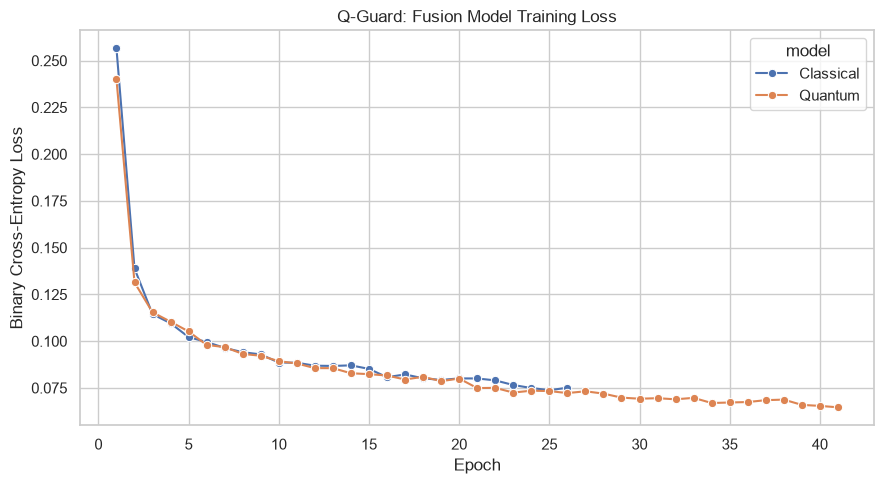

In [35]:
plot_history = pd.concat([
    classical_fusion_history,
    quantum_history
], ignore_index=True)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=plot_history,
    x="epoch",
    y="train_loss",
    hue="model",
    marker="o"
)

plt.title("Q-Guard: Fusion Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
save_plot("Fusion_Model_Training_Loss")

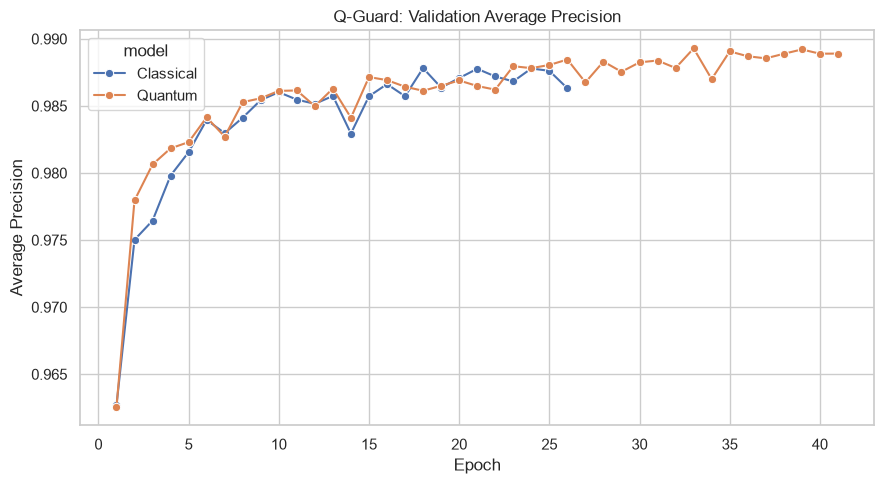

In [36]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=plot_history,
    x="epoch",
    y="val_ap",
    hue="model",
    marker="o"
)

plt.title("Q-Guard: Validation Average Precision")
plt.xlabel("Epoch")
plt.ylabel("Average Precision")
save_plot("Validatio_AP")

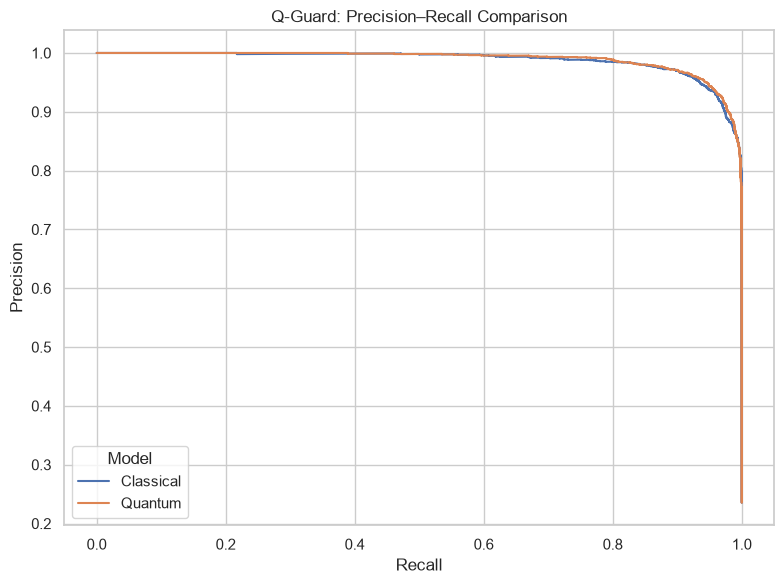

In [37]:
pr_records = []

for name, result in [
    ("Classical", classical_result),
    ("Quantum", quantum_result)
]:
    precision, recall, _ = precision_recall_curve(
        result["y_true"],
        result["y_score"]
    )

    pr_records.extend([
        {
            "Model": name,
            "Recall": r,
            "Precision": p
        }
        for p, r in zip(precision, recall)
    ])

pr_df = pd.DataFrame(pr_records)

plt.figure(figsize=(8, 6))

sns.lineplot(
    data=pr_df,
    x="Recall",
    y="Precision",
    hue="Model",
    estimator=None
)

plt.title("Q-Guard: Precision–Recall Comparison")
save_plot("Precision–Recall_Comparison")

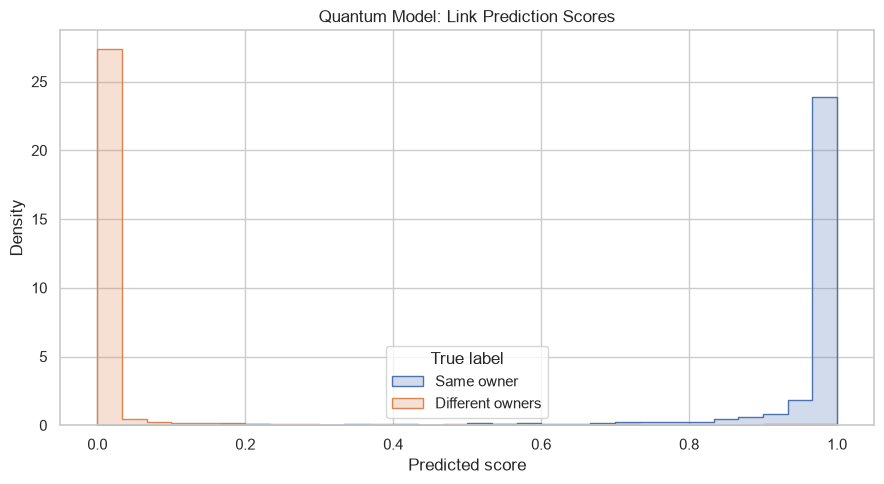

In [38]:
score_df = pd.DataFrame({
    "Score": quantum_result["y_score"],
    "True label": np.where(
        quantum_result["y_true"] == 1,
        "Same owner",
        "Different owners"
    )
})

plt.figure(figsize=(9, 5))

sns.histplot(
    data=score_df,
    x="Score",
    hue="True label",
    bins=30,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Quantum Model: Link Prediction Scores")
plt.xlabel("Predicted score")
plt.ylabel("Density")
save_plot("Link_Prediction_Scores")

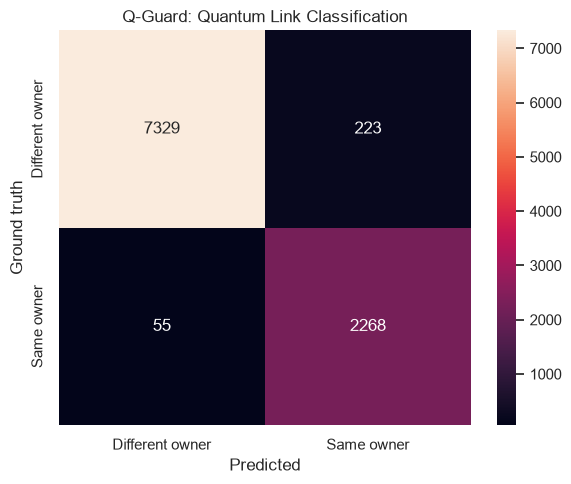

In [39]:
y_true = quantum_result["y_true"]

y_pred = (
    quantum_result["y_score"] >= 0.5
).astype(int)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Different owner", "Same owner"],
    yticklabels=["Different owner", "Same owner"]
)

plt.title("Q-Guard: Quantum Link Classification")
plt.xlabel("Predicted")
plt.ylabel("Ground truth")
save_plot("Confusion_matrix")

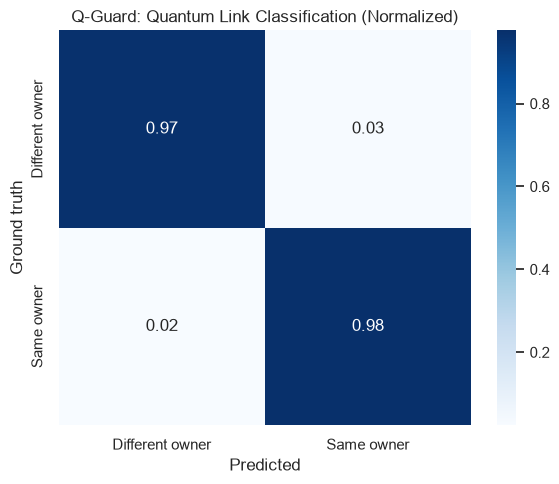

In [40]:
y_true = quantum_result["y_true"]

y_pred = (
    quantum_result["y_score"] >= 0.5
).astype(int)

cm_norm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
    normalize="true"   # row-wise normalization
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=["Different owner", "Same owner"],
    yticklabels=["Different owner", "Same owner"]
)

plt.title("Q-Guard: Quantum Link Classification (Normalized)")
plt.xlabel("Predicted")
plt.ylabel("Ground truth")

save_plot("confusion_matrix_normalized")

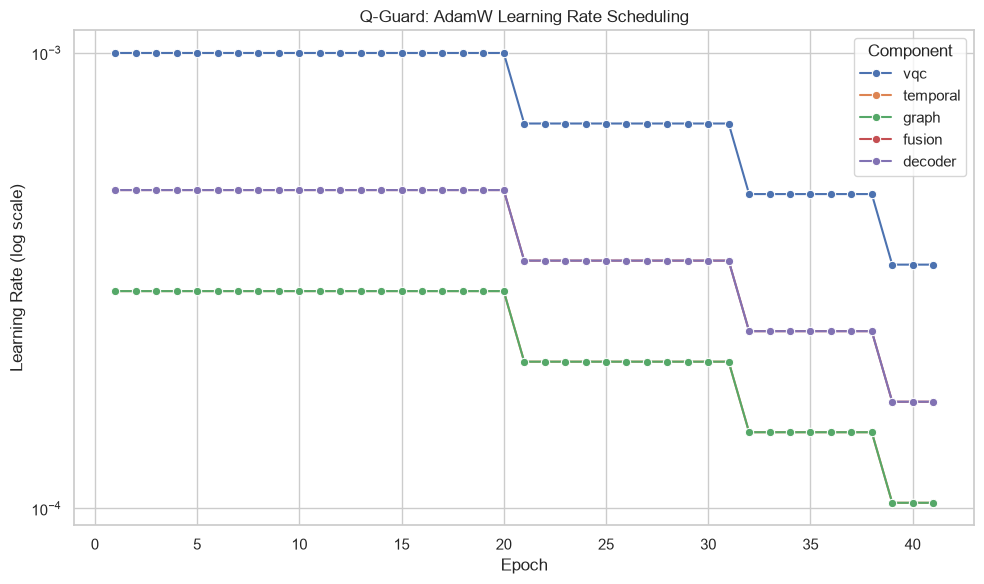

In [41]:
lr_columns = [
    "lr_vqc",
    "lr_temporal",
    "lr_graph",
    "lr_fusion",
    "lr_decoder"
]

lr_df = quantum_history.melt(
    id_vars="epoch",
    value_vars=lr_columns,
    var_name="Component",
    value_name="Learning Rate"
)

lr_df["Component"] = (
    lr_df["Component"]
    .str.replace("lr_", "", regex=False)
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=lr_df,
    x="epoch",
    y="Learning Rate",
    hue="Component",
    marker="o"
)

plt.yscale("log")

plt.title("Q-Guard: AdamW Learning Rate Scheduling")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate (log scale)")

save_plot("quantum_learning_rates")

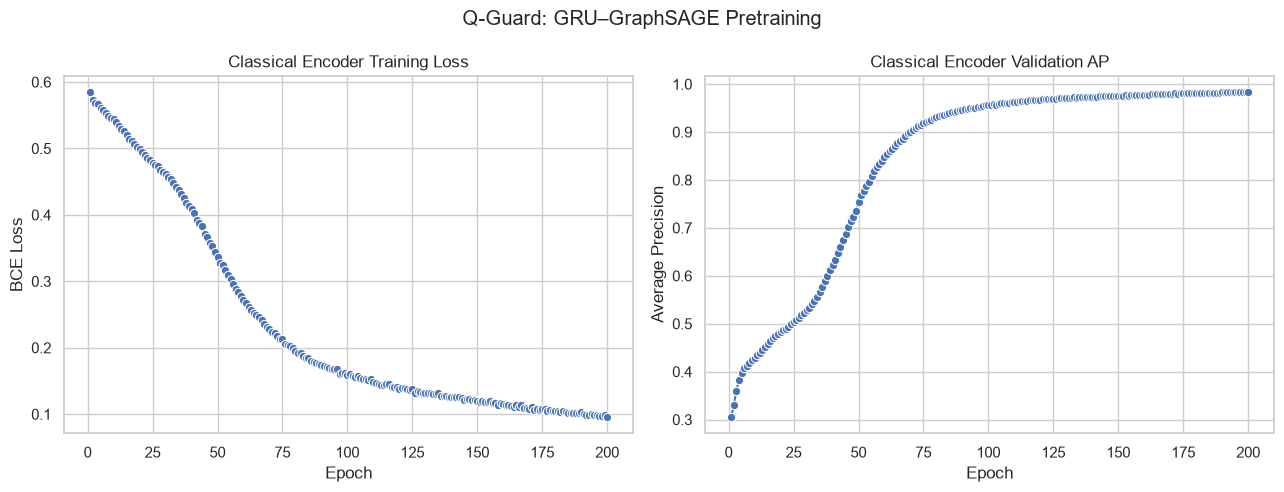

In [42]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

sns.lineplot(
    data=classical_history,
    x="epoch",
    y="train_loss",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Classical Encoder Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")

sns.lineplot(
    data=classical_history,
    x="epoch",
    y="val_ap",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Classical Encoder Validation AP")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Average Precision")

fig.suptitle("Q-Guard: GRU–GraphSAGE Pretraining")

save_plot("classical_encoder_pretraining")

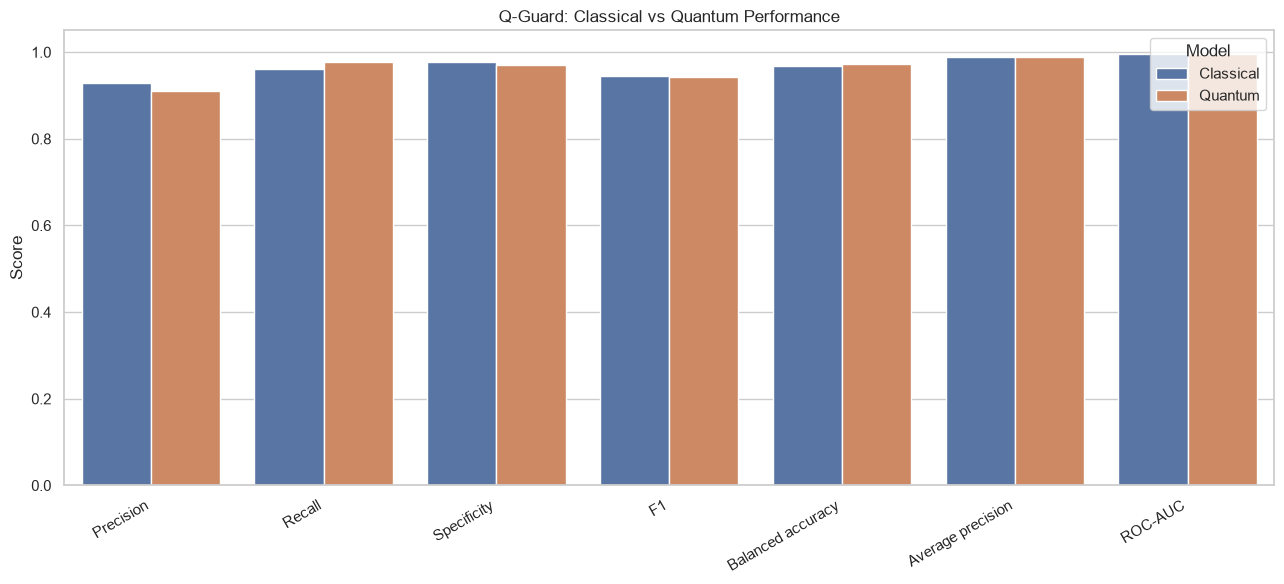

In [43]:
metric_columns = [
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Balanced accuracy",
    "Average precision",
    "ROC-AUC"
]

plot_df = metrics.melt(
    id_vars="Model",
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")

plt.title("Q-Guard: Classical vs Quantum Performance")
plt.xlabel("")
plt.ylabel("Score")

save_plot("model_metrics_comparison")

In [44]:
for name, result in [
    ("Classical", classical_result),
    ("Quantum", quantum_result)
]:
    y_true = result["y_true"]
    y_pred = (result["y_score"] >= 0.5).astype(int)

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Different owner",
            "Same owner"
        ],
        output_dict=True,
        zero_division=0
    )

In [47]:
idx_to_val_account = {
    index: account_id
    for account_id, index in val_map.items()
}

# Observable validation data only
sessions = val_view["sessions"].copy()
payments = val_view["payment_events"].copy()
transactions = val_view["transactions"].copy()

# Exclude public networks from linkage evidence
nonpublic_sessions = sessions[
    sessions["network_id"].map(network_types) != "public"
].copy()


def account_sets(frame, column):
    return (
        frame.dropna(subset=["account_id", column])
        .groupby("account_id")[column]
        .agg(lambda values: set(values.astype(str)))
        .to_dict()
    )


device_lookup = account_sets(sessions, "device_id")
network_lookup = account_sets(nonpublic_sessions, "network_id")
payment_lookup = account_sets(payments, "payment_token")

In [48]:
tx_summary = (
    transactions
    .groupby("account_id")
    .agg(
        transaction_count=("amount_cad", "size"),
        transaction_total_cad=("amount_cad", "sum"),
        last_transaction_utc=("timestamp", "max")
    )
    .to_dict("index")
)


def get_transaction_summary(account_id):
    row = tx_summary.get(account_id, {})

    return {
        "transaction_count": int(
            row.get("transaction_count", 0)
        ),
        "transaction_total_cad": float(
            row.get("transaction_total_cad", 0.0)
        ),
        "last_transaction_utc": str(
            row.get("last_transaction_utc", "")
        )
    }


def common_values(lookup, a, b):
    values = lookup.get(a, set()) & lookup.get(b, set())
    return "|".join(sorted(values))

In [49]:
scores = quantum_result["y_score"]

if len(scores) != len(val_pairs):
    raise ValueError("Prediction and pair counts do not match")

cases = []

for (i, j), score in zip(val_pairs, scores):

    a = idx_to_val_account[int(i)]
    b = idx_to_val_account[int(j)]

    # Stable identifier for this account pair
    pair_key = "|".join(sorted([str(a), str(b)]))

    case_id = "QG-" + hashlib.sha256(
        pair_key.encode("utf-8")
    ).hexdigest()[:12].upper()

    a_summary = get_transaction_summary(a)
    b_summary = get_transaction_summary(b)

    cases.append({
        "case_id": case_id,
        "account_a": a,
        "account_b": b,
        "link_score": float(score),

        "shared_devices": common_values(
            device_lookup, a, b
        ),
        "shared_networks": common_values(
            network_lookup, a, b
        ),
        "shared_payments": common_values(
            payment_lookup, a, b
        ),

        "a_transaction_count":
            a_summary["transaction_count"],
        "b_transaction_count":
            b_summary["transaction_count"],

        "a_transaction_total_cad":
            a_summary["transaction_total_cad"],
        "b_transaction_total_cad":
            b_summary["transaction_total_cad"],

        "a_last_transaction_utc":
            a_summary["last_transaction_utc"],
        "b_last_transaction_utc":
            b_summary["last_transaction_utc"]
    })


cases_df = (
    pd.DataFrame(cases)
    .sort_values("link_score", ascending=False)
    .reset_index(drop=True)
)

cases_df.to_csv(
    EXPORT_DIR / "cases.csv",
    index=False
)

display(cases_df.head(10))

,case_id,account_a,account_b,link_score,shared_devices,shared_networks,shared_payments,a_transaction_count,b_transaction_count,a_transaction_total_cad,b_transaction_total_cad,a_last_transaction_utc,b_last_transaction_utc
0,QG-F28508DBE335,A0013970,A0041683,0.999985,D606f2c9551cba2e1e00cf3c3,N60098272201836f295bad750|N6d332cd9d9cd558a746...,PAYeaeb21acfd7909956f118499,161,132,9342.47,8013.89,2026-09-28 14:26:00+00:00,2026-09-26 20:56:00+00:00
1,QG-BF7C5D2DC024,A0011733,A0018923,0.999969,D6d39346bc23b8cc79bf13df3|D958d8684a5e86db354e...,N0e366b47148319e37d22f00e|N8a57078dfc6c685a8a4...,PAYdba8b402ff27081f219c0b50,66,50,6999.88,5778.32,2026-09-24 19:29:00+00:00,2026-09-27 16:37:00+00:00
2,QG-382D4587574B,A0037767,A0057762,0.999968,D2529f3e41c0e352901c88142,N06b7a039ad337af11bc58f9a|N3d2b3c903eac7a7c63a...,PAY8fba9c55b4146fe9b641abf2,85,70,8336.74,7444.48,2026-09-28 15:49:00+00:00,2026-09-26 09:32:00+00:00
3,QG-DE96636C1FF8,A0000860,A0005831,0.999966,D54a19385164f2b517d082e80,N1f3e7cfaee295a279f89ccd7|Nd7e2b92e77684b4ea3f...,PAY59999ec2a46f208c80772379,144,52,6182.07,1996.72,2026-09-28 17:55:00+00:00,2026-09-27 20:53:00+00:00
4,QG-EE373A4B6CFD,A0044493,A0046485,0.999962,Dfeb003a7b66d117300045542,N0a1b76ebfe4fd9d0c307045e|Nf74c328a07ed43efe9b...,PAY268354098e2f0ffd19f802ae,118,15,10061.85,1139.97,2026-09-28 20:05:00+00:00,2026-09-20 01:14:00+00:00
5,QG-0BB116D7DACB,A0012686,A0044809,0.999958,D4fbbb038e9718bde12477afd|Dfe1cfe513aebb06a009...,N178272df499fe06d42c3d9d4|N7b70328471e02a10449...,PAY7e5f2a91044d40b35683a909,327,96,26011.31,6977.05,2026-09-28 21:52:00+00:00,2026-09-28 16:49:00+00:00
6,QG-6A97A0D81AA7,A0042456,A0049215,0.999954,D6b4fb24472cac75f207ea4f8,N21584209ef98c1f3b37b7a5a|Ne410abc9325705b21f3...,PAY0cb773975901657e322ab669,29,86,1419.75,4584.25,2026-09-28 00:00:00+00:00,2026-09-25 23:22:00+00:00
7,QG-E1E055CB3F3A,A0000558,A0021604,0.999953,Ddf129c0555f8281d90619c3c,N406a7a07d48bd8b9028c481a|N40be91697ae22e4e0d2...,PAY33ad4f843bfd41c8f1b375ee,177,28,17322.16,3271.87,2026-09-28 22:01:00+00:00,2026-09-20 18:47:00+00:00
8,QG-E99ECBE3F0A8,A0005905,A0018614,0.999950,D3dbdad78a315840d7cfb604f|D8c732906e91c35bd2db...,Ndef9e20daf514ceca028d311|Necd39b84a529160b79b...,PAY5cd15c669b4b476050f9f6ca,77,21,5617.59,1598.73,2026-09-27 02:45:00+00:00,2026-09-25 02:45:00+00:00
9,QG-2D438F3B67E6,A0018083,A0033717,0.999943,,N9d0ad69c0aa586863b11c262|N9d702e18f9de9b554dc...,PAY59ff0fa57426db5073bc7f14,14,266,481.54,9997.47,2026-09-24 19:39:00+00:00,2026-09-28 23:42:00+00:00
